## This code is for generating bifurcation diagrams for both continuous and discrete time dynamical systems. 

# Lorenz Attractor

The Lorenz system is one of the most well-known examples of a continuous-time dynamical system exhibiting chaotic behavior. It is governed by the equations

$$
\begin{aligned}
\dot{x} &= \sigma (y-x),\\
\dot{y} &= x(\rho-z)-y,\\
\dot{z} &= xy-\beta z,
\end{aligned}
$$

where $\sigma$, $\rho$, and $\beta$ are system parameters. Throughout this example, $\rho$ is used as the bifurcation parameter.

### Bifurcation Diagram

Unlike discrete-time systems, a continuous-time trajectory evolves continuously in phase space and does not consist of isolated iterates. Therefore, the bifurcation diagram is constructed by recording the **local maxima (or minima)** of a state variable after the transient dynamics have decayed. As the parameter $\rho$ is varied, the distribution of these extrema reveals the transitions between periodic and chaotic dynamics.


In [40]:
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from scipy.integrate import odeint

plt.rcParams.update(
    {
        "font.size": 18,
        "axes.labelsize": 20,
        "axes.titlesize": 20,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "text.usetex": True,
    }
)

# Lorenz parameters
sigma = 10
beta = 8 / 3
rho_values = np.arange(125, 325, 0.25)

t_transient = np.linspace(0, 120, 6000)

t_collect = np.linspace(0, 30, 6000)

x0, y0, z0 = 1.0, 1.0, 1.0


def lorenz(state, t, rho):
    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return [dx, dy, dz]


rho_axis = []
z_axis = []

for rho in tqdm(rho_values):
   
    sol_transient = odeint(
        lorenz, [x0, y0, z0], t_transient, args=(rho,), atol=1e-11, rtol=1e-9
    )


    settled_state = sol_transient[-1]

    sol_collect = odeint(
        lorenz, settled_state, t_collect, args=(rho,), atol=1e-11, rtol=1e-9
    )
    z = sol_collect[:, 2]

 
    peaks = (z[1:-1] > z[:-2]) & (z[1:-1] > z[2:])
    peak_values = z[1:-1][peaks]

    rho_axis.extend([rho] * len(peak_values))
    z_axis.extend(peak_values)
    x0, y0, z0 = settled_state



100%|█████████████████████████████████████████| 800/800 [05:12<00:00,  2.56it/s]


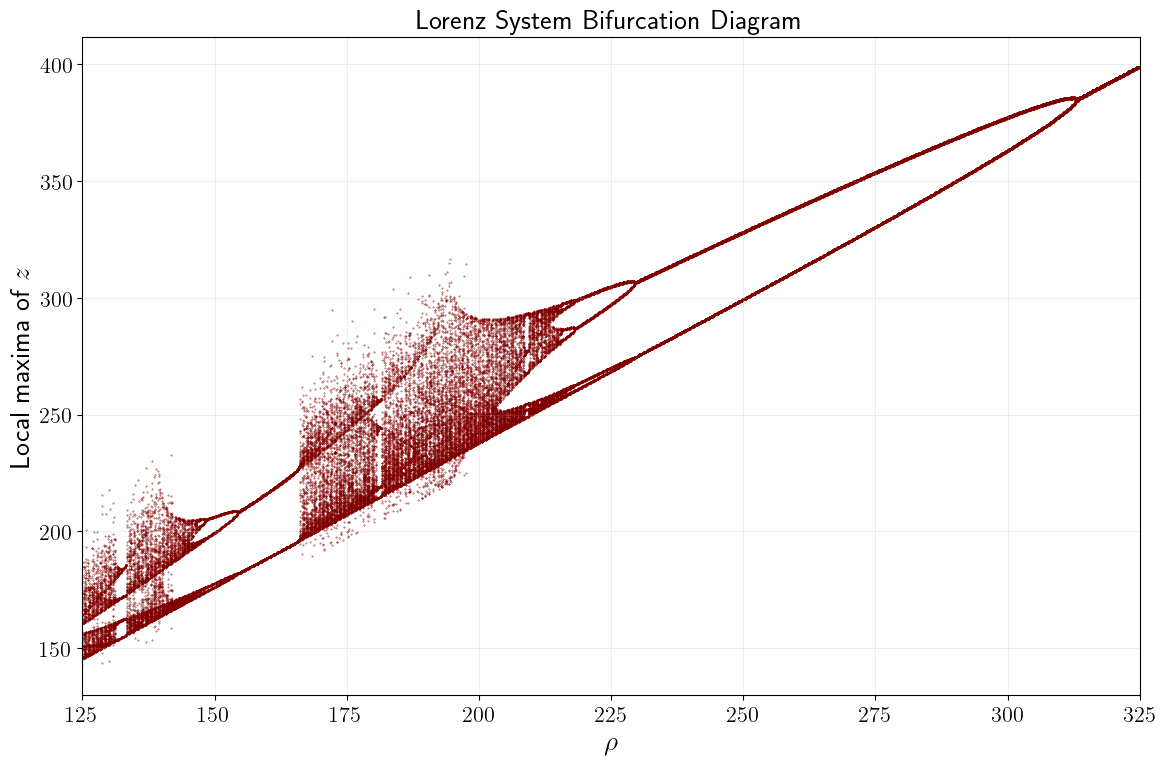

In [42]:
plt.figure(figsize=(12, 8))
plt.scatter(
    rho_axis,
    z_axis,
    color="maroon",
    marker=".",
    s=0.5,
    alpha=0.8,
)

plt.xlabel(r"$\rho$")
plt.ylabel(r"Local maxima of $z$")
plt.title(r"Lorenz System Bifurcation Diagram")
plt.xlim(125, 325)
plt.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

# Logistic Map and Crisis

The logistic map is a simple one-dimensional discrete-time system described by

$$
x_{n+1}=\mu x_n(1-x_n), \qquad x_n\in[0,1],
$$

where $\mu$ is the bifurcation parameter.  As $\mu$ is varied, the bifurcation diagram reveals the onset of chaos through a cascade of period-doubling bifurcations, followed by a sequence of attractor-merging crises in the interval ($3.57<\mu<3.68$), where multiple chaotic bands successively merge into a single chaotic attractor. An interior crisis occurs at ($\mu\approx3.8568$), where the chaotic attractor suddenly expands due to its collision with an unstable period-3 orbit. Finally, at ($\mu=4$), the chaotic attractor collides with the unstable fixed point ($x^*=0$), resulting in a boundary crisis beyond which trajectories eventually escape to ($-\infty$).


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve  # Added for root-finding functionality

mu_coarse = np.arange(3, 3.5, 0.004)   # coarse step
mu_fine   = np.arange(3.5, 4.0, 0.0008)  # fine step
mu = np.concatenate([mu_coarse, mu_fine])  # merge

nt = 500
broadcast_shapee = 20

# Prepare mu broadcasted
mu_repeated = np.repeat(mu, broadcast_shapee)
mu_broadcasted = mu_repeated.reshape(len(mu), broadcast_shapee)

x_list1 = np.zeros((len(mu), broadcast_shapee))
for j in range(len(mu)):
    x = 0.7
    for _ in range(nt):  # warm up
        x = mu[j] * x - mu[j] * x**2
    for k in range(broadcast_shapee):
        x = mu[j] * x - mu[j] * x**2
        x_list1[j, k] = x

#  Unstable Period-3 Orbit Calculation
def f(x, mu_val):
    return mu_val * x * (1 - x)

def f2(x, mu_val):
    return f(f(x, mu_val), mu_val)

def f3(x, mu_val):
    return f(f2(x, mu_val), mu_val)

a = 1 + 2 * np.sqrt(2) # Period-3 birth parameter threshold (~3.8284)
mu_vals_unstable = []
x_vals_unstable = []

for m in mu:
    # Only look for period-3 orbits where they physically exist
    if m >= a and m<=3.858:
        guesses = np.linspace(0, 1, 100)
        roots = []
        for g in guesses:
            try:
                r = fsolve(lambda x: f3(x, m) - x, g)[0]
                # 1. Keep only valid range
                if 0 <= r <= 1:
                    # Verify fsolve actually found a valid root of f3(x) - x = 0
                    if abs(f3(r, m) - r) < 1e-5:
                        # 2. Exclude fixed points (period-1)
                        if abs(f(r, m) - r) > 1e-4:
                            # 3. Calculate multiplier (derivative of f^3 at r)
                            mult = abs((m * (1 - 2 * r)) *
                                       (m * (1 - 2 * f(r, m))) *
                                       (m * (1 - 2 * f2(r, m))))
                            # 4. Filter for instability
                            if mult > 1:
                                # Remove duplicates
                                if all(abs(r - rr) > 1e-4 for rr in roots):
                                    roots.append(r)
            except:
                pass
        for r in roots:
            mu_vals_unstable.append(m)
            x_vals_unstable.append(r)

/tmp/ipykernel_722866/2683159053.py:46: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  r = fsolve(lambda x: f3(x, m) - x, g)[0]


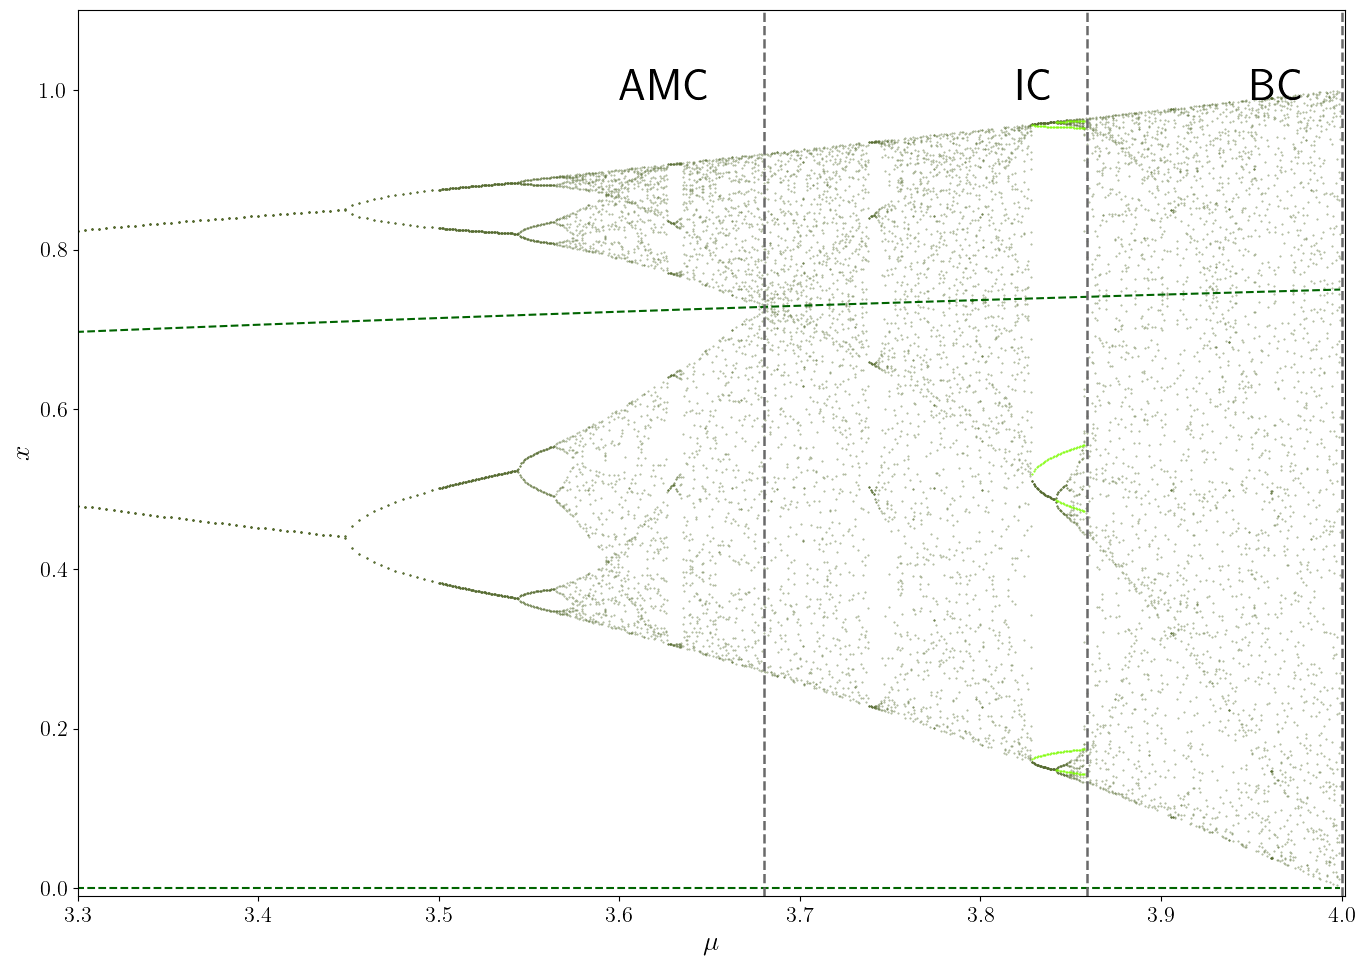

In [48]:

plt.figure(figsize=(14, 10))

# Plot bifurcation diagram
for j in range(len(mu)):
    plt.scatter(mu_broadcasted[j, :], x_list1[j, :],
             color='darkolivegreen', s=0.7, marker='.', alpha=0.6)

plt.plot(mu_vals_unstable, x_vals_unstable, color='lawngreen', ls='', marker='.', markersize=1)


# Dashed lines: x = 0 and x = 1 - 1/mu (two fixed points)
valid_mu = mu[mu > 1]
plt.plot(valid_mu, 0*valid_mu, color='darkgreen', ls='--', lw=1.5,
         label=r"$x = 0$")
plt.plot(valid_mu, 1 - 1 / valid_mu, color='darkgreen', ls='--', lw=1.5,
         label=r"$x = 1 - \frac{1}{\mu}$")

# Vertical lines
plt.axvline(4, color='dimgrey', ls='--', lw=1.8, label=r"$\mu = 4$")
plt.axvline(3.68, color='dimgrey', ls='--', lw=1.8, label=r"$\mu \approx 3.68$")
plt.axvline(3.859, color='dimgrey', ls='--', lw=1.8, label=r"$\mu \approx 3.84$")

plt.text(3.95, 1, "BC", fontsize=32, rotation=0, va='center')
plt.text(3.6, 1, "AMC", fontsize=32, rotation=0, va='center')
plt.text(3.82, 1, "IC", fontsize=32, rotation=0, va='center')
# Labels and style
plt.xlabel(r"$\mu$")
plt.ylabel(r"$x$")
plt.xlim(3.3 , 4.002)
plt.ylim(-0.01, 1.1)
plt.tight_layout()

plt.show()